<a href="https://colab.research.google.com/github/Lelash-P/WebsiteTrafficForecasting-1/blob/main/WebsiteTrafficForecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from google.colab import files

np.random.seed(42)
tf.random.set_seed(42)

uploaded = files.upload()   # choose Time-Series_Data.csv

Saving Time-Series Data.csv to Time-Series Data (1).csv


Reading data from: Time-Series Data.csv
Rows: 421 | Missing values before fix: 0
Missing values after fix: 0
             users
count   421.000000
mean   2791.660333
std    1091.553358
min     133.000000
25%    2100.000000
50%    2560.000000
75%    3435.000000
max    6807.000000


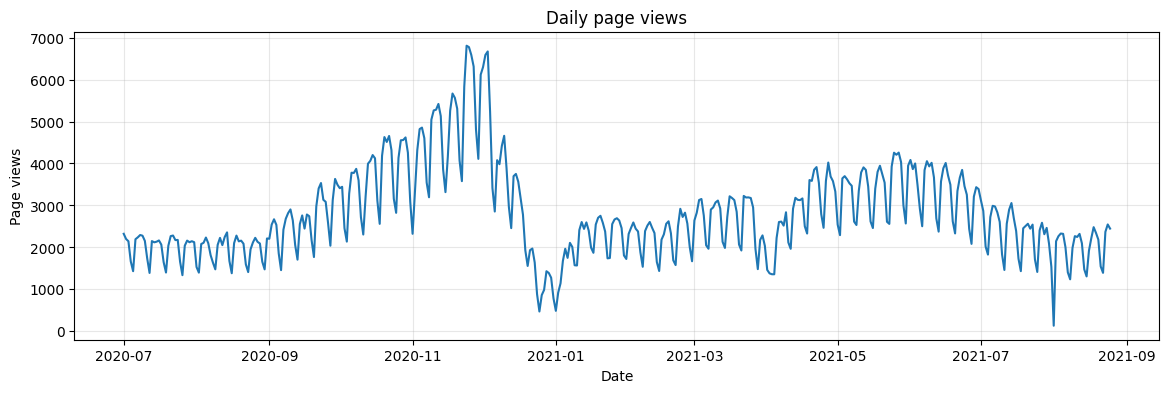

In [ ]:
df = pd.read_csv("Time-Series_Data.csv")
df["date"] = pd.to_datetime(df["date"], format="%d/%m/%y")
df = df.sort_values("date").drop_duplicates("date").set_index("date")

# Force a complete daily index so any missing days become explicit NaNs
df = df.asfreq("D")
print("Rows:", len(df), "| Missing values before fix:", df["users"].isna().sum())

# Fill gaps: time-based interpolation (traffic is continuous), edges filled by ffill/bfill
df["users"] = df["users"].interpolate(method="time").ffill().bfill()
print("Missing values after fix:", df["users"].isna().sum())

print(df.describe())

plt.figure(figsize=(14, 4))
plt.plot(df.index, df["users"])
plt.title("Daily page views")
plt.xlabel("Date"); plt.ylabel("Page views")
plt.grid(alpha=0.3)
plt.show()

In [ ]:
WINDOW = 14      # use past 14 days to predict the next day
n = len(df)
train_end = int(n * 0.70)
val_end   = int(n * 0.85)

values = df["users"].values.reshape(-1, 1)

# Fit scaler on TRAIN only (avoids data leakage)
scaler = MinMaxScaler()
scaler.fit(values[:train_end])
scaled = scaler.transform(values).flatten()

# Calendar features: day of week as sin/cos
dow = df.index.dayofweek.values
dow_sin = np.sin(2 * np.pi * dow / 7)
dow_cos = np.cos(2 * np.pi * dow / 7)

features = np.column_stack([scaled, dow_sin, dow_cos])   # shape (n, 3)
print("Train / Val / Test days:", train_end, val_end - train_end, n - val_end)

Train / Val / Test days: 294 63 64


In [ ]:
def make_sequences(features, target, window):
    X, y = [], []
    for i in range(window, len(features)):
        X.append(features[i - window:i])
        y.append(target[i])
    return np.array(X), np.array(y)

X_all, y_all = make_sequences(features, scaled, WINDOW)
target_idx = np.arange(WINDOW, n)          # index of the day each sequence predicts

train_mask = target_idx < train_end
val_mask   = (target_idx >= train_end) & (target_idx < val_end)
test_mask  = target_idx >= val_end

X_train, y_train = X_all[train_mask], y_all[train_mask]
X_val,   y_val   = X_all[val_mask],   y_all[val_mask]
X_test,  y_test  = X_all[test_mask],  y_all[test_mask]

print("X_train:", X_train.shape, "X_val:", X_val.shape, "X_test:", X_test.shape)

X_train: (280, 14, 3) X_val: (63, 14, 3) X_test: (64, 14, 3)


In [ ]:
model = models.Sequential([
    layers.Input(shape=(WINDOW, X_train.shape[2])),
    layers.LSTM(64, return_sequences=True),
    layers.Dropout(0.2),
    layers.LSTM(32),
    layers.Dense(16, activation="relu"),
    layers.Dense(1)
])
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse")
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 14, 64)         │        17,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 14, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,369 (118.63 KB)

 Trainable params: 30,369 (118.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - loss: 0.0482 - val_loss: 0.0072 - learning_rate: 0.0010
Epoch 2/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0163 - val_loss: 0.0041 - learning_rate: 0.0010
Epoch 3/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0116 - val_loss: 0.0045 - learning_rate: 0.0010
Epoch 4/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0115 - val_loss: 0.0028 - learning_rate: 0.0010
Epoch 5/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0107 - val_loss: 0.0026 - learning_rate: 0.0010
Epoch 6/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0100 - val_loss: 0.0033 - learning_rate: 0.0010
Epoch 7/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0097 - val_loss: 0.0044 - learning_rate: 0.0010
Epoch 8/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0104 - val_loss: 0.0027 - learning_rate: 0.0010
Epoch 9/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0098 - val_loss: 0.0027 - learning_rate: 0.0010
Epoch 10/2

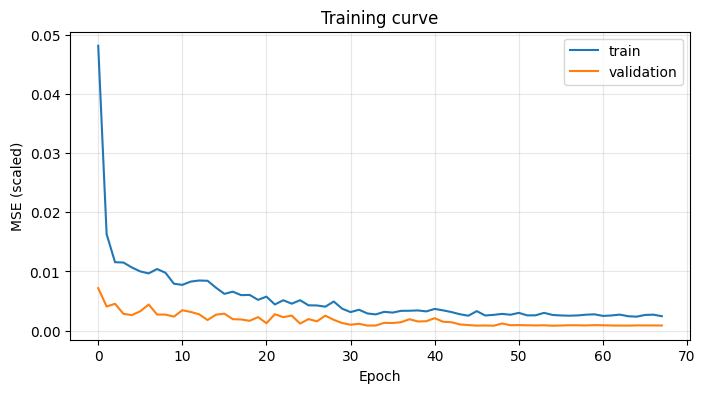

In [ ]:
cbs = [
    callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=8, min_lr=1e-5)
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=200,
    batch_size=16,
    callbacks=cbs,
    shuffle=False,      # keep temporal order
    verbose=1
)

plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.title("Training curve"); plt.xlabel("Epoch"); plt.ylabel("MSE (scaled)")
plt.legend(); plt.grid(alpha=0.3); plt.show()

In [ ]:
def inverse(a):
    return scaler.inverse_transform(np.array(a).reshape(-1, 1)).flatten()

pred_test = inverse(model.predict(X_test, verbose=0))
actual_test = inverse(y_test)

# Baseline: same weekday last week
test_positions = target_idx[test_mask]
baseline_test = values[test_positions - 7].flatten()

def report(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    print(f"{name:<22} MAE: {mae:8.2f} | RMSE: {rmse:8.2f}")

report("LSTM (test set)", actual_test, pred_test)
report("Seasonal-naive (t-7)", actual_test, baseline_test)

LSTM (test set)        MAE:   151.34 | RMSE:   236.54
Seasonal-naive (t-7)   MAE:   223.00 | RMSE:   316.27


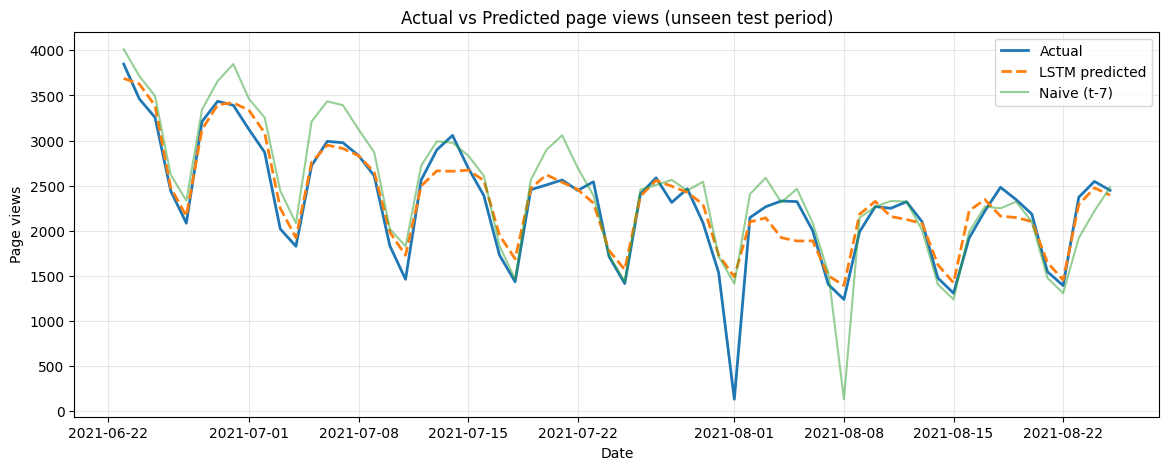

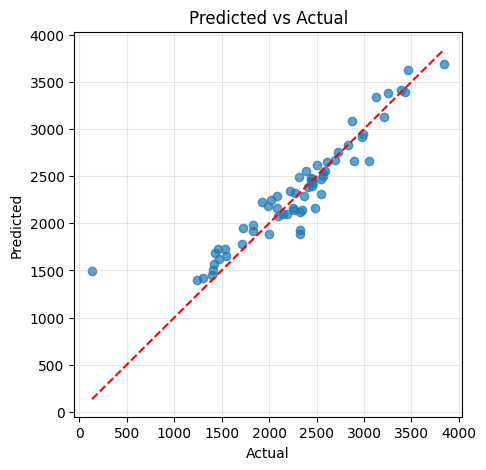

In [ ]:
test_dates = df.index[test_positions]

plt.figure(figsize=(14, 5))
plt.plot(test_dates, actual_test, label="Actual", linewidth=2)
plt.plot(test_dates, pred_test, label="LSTM predicted", linewidth=2, linestyle="--")
plt.plot(test_dates, baseline_test, label="Naive (t-7)", alpha=0.5)
plt.title("Actual vs Predicted page views (unseen test period)")
plt.xlabel("Date"); plt.ylabel("Page views")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

# Scatter: how close are predictions to the diagonal?
plt.figure(figsize=(5, 5))
plt.scatter(actual_test, pred_test, alpha=0.7)
lims = [min(actual_test.min(), pred_test.min()), max(actual_test.max(), pred_test.max())]
plt.plot(lims, lims, "r--")
plt.xlabel("Actual"); plt.ylabel("Predicted"); plt.title("Predicted vs Actual")
plt.grid(alpha=0.3); plt.show()

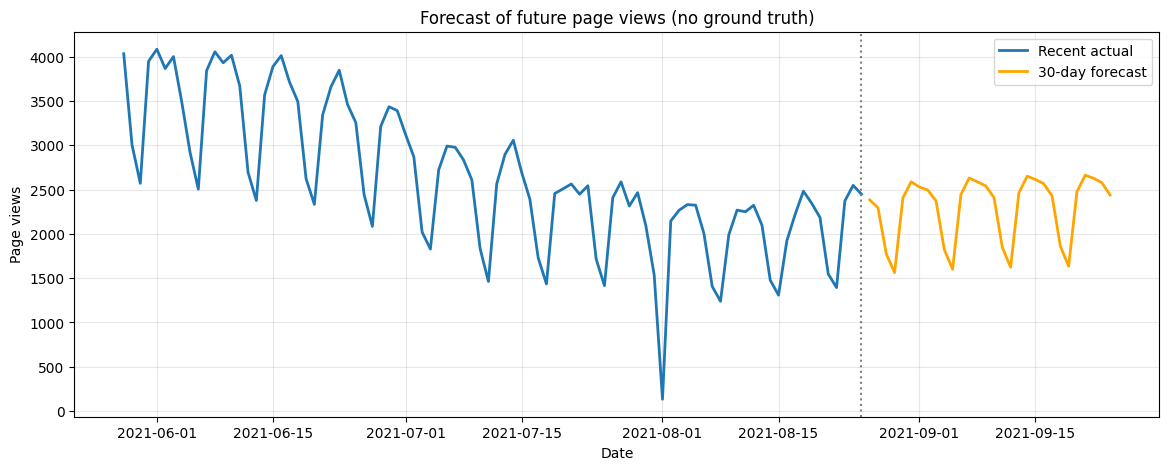

        date  predicted_views
0 2021-08-26           2383.0
1 2021-08-27           2293.0
2 2021-08-28           1774.0
3 2021-08-29           1562.0
4 2021-08-30           2404.0
5 2021-08-31           2588.0
6 2021-09-01           2528.0
7 2021-09-02           2494.0
8 2021-09-03           2373.0
9 2021-09-04           1822.0


In [ ]:
# Recursive forecast: predict one day, feed it back in, repeat
HORIZON = 30
window_feat = features[-WINDOW:].copy()
last_date = df.index[-1]
future_dates, future_preds = [], []

for step in range(HORIZON):
    x = window_feat.reshape(1, WINDOW, -1)
    p_scaled = model.predict(x, verbose=0)[0, 0]
    next_date = last_date + pd.Timedelta(days=step + 1)
    d = next_date.dayofweek
    new_row = np.array([p_scaled, np.sin(2*np.pi*d/7), np.cos(2*np.pi*d/7)])
    window_feat = np.vstack([window_feat[1:], new_row])
    future_dates.append(next_date)
    future_preds.append(p_scaled)

future_preds = inverse(future_preds)

plt.figure(figsize=(14, 5))
plt.plot(df.index[-90:], df["users"].values[-90:], label="Recent actual", linewidth=2)
plt.plot(future_dates, future_preds, label=f"{HORIZON}-day forecast", linewidth=2, color="orange")
plt.axvline(last_date, color="gray", linestyle=":")
plt.title("Forecast of future page views (no ground truth)")
plt.xlabel("Date"); plt.ylabel("Page views")
plt.legend(); plt.grid(alpha=0.3); plt.show()

print(pd.DataFrame({"date": future_dates, "predicted_views": future_preds.round(0)}).head(10))